### Names, ID: Ritaj Alhosawi 446007287, Hala Alrefe 446016956, Yumna Yasser 446004806, Mayar Matook 446003113, Joud Al-hadrmi 44610611

In [1]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

### 1 Data loading & Inspection

**Data Loading**

In [2]:
df = pd.read_excel('/kaggle/input/datasets/mukuldeshantri/hotels-netherlands/HotelFinalDataset.xlsx')

**Data Inspection**

In [3]:
df.head()

,Unnamed: 0,Name,Place,Type,Price,ReviewsCount,Rating,City,State
0,0,BUNK Hotel Amsterdam,"Amsterdam Noord, Amsterdam",Bunk Pod for 2,"₹ 7,887",778.0,8.4,Amsterdam Noord,Amsterdam
1,1,YOTEL Amsterdam,"Amsterdam Noord, Amsterdam",Premium Double Room,"₹ 15,267",500.0,8.1,Amsterdam Noord,Amsterdam
2,2,Multatuli Hotel,"Amsterdam City Center, Amsterdam",Double Room,"₹ 13,063",1605.0,7.4,Amsterdam City Center,Amsterdam
3,3,nhow Amsterdam Rai,"Zuideramstel, Amsterdam",nhow Double or Twin Room with View,"₹ 12,854",500.0,9.0,Zuideramstel,Amsterdam
4,4,Motel One Amsterdam,"Zuideramstel, Amsterdam",Double Room,"₹ 9,471",500.0,8.8,Zuideramstel,Amsterdam


In [4]:
df.shape

(525, 9)

In [5]:
df.columns

Index(['Unnamed: 0', 'Name', 'Place', 'Type', 'Price', 'ReviewsCount',
       'Rating', 'City', 'State'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525 entries, 0 to 524
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    525 non-null    int64  
 1   Name          525 non-null    object 
 2   Place         525 non-null    object 
 3   Type          525 non-null    object 
 4   Price         525 non-null    object 
 5   ReviewsCount  512 non-null    float64
 6   Rating        515 non-null    float64
 7   City          525 non-null    object 
 8   State         133 non-null    object 
dtypes: float64(2), int64(1), object(6)
memory usage: 37.0+ KB


In [7]:
df.describe()

,Unnamed: 0,ReviewsCount,Rating
count,525.000000,512.000000,515.000000
mean,262.000000,736.556641,8.331456
std,151.698715,879.553639,0.711974
min,0.000000,1.000000,3.700000
25%,131.000000,239.000000,8.000000
50%,262.000000,500.000000,8.400000
75%,393.000000,888.000000,8.800000
max,524.000000,7748.000000,10.000000


### 2 Data Quality Assessment

In [8]:
df.rename(columns={'Price':'Hotel_Price'}, inplace=True)

In [9]:
df.dtypes

Unnamed: 0        int64
Name             object
Place            object
Type             object
Hotel_Price      object
ReviewsCount    float64
Rating          float64
City             object
State            object
dtype: object

In [10]:
df['Hotel_Price'] = pd.to_numeric(df['Hotel_Price'], errors='coerce')
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df['ReviewsCount'] = pd.to_numeric(df['ReviewsCount'], errors='coerce')

print(df.dtypes)

Unnamed: 0        int64
Name             object
Place            object
Type             object
Hotel_Price     float64
ReviewsCount    float64
Rating          float64
City             object
State            object
dtype: object


Data types were fixed because numerical columns must be numeric to calculate statistics, averages, and correlations.

**1  check and handle missing values**

In [11]:
# Check missing values and display only columns with missing data
missing = df.isnull().sum()
missing = missing[missing > 0]

print("Columns with missing values:\n")
print(missing)

Columns with missing values:

Hotel_Price     525
ReviewsCount     13
Rating           10
State           392
dtype: int64


In [12]:
df_drop = df.dropna()
print("Missing after drop method:", df_drop.isnull().sum().sum())
print("Rows after drop method:", len(df_drop))

Missing after drop method: 0
Rows after drop method: 0


In [13]:
df_clean = df.copy()

df_clean['Rating'] = df_clean['Rating'].fillna(df_clean['Rating'].median())
df_clean['ReviewsCount'] = df_clean['ReviewsCount'].fillna(df_clean['ReviewsCount'].median())
df_clean['State'] = df_clean['State'].fillna(df_clean['State'].mode()[0])

print("Missing after median/mode method:")
print(df_clean.isnull().sum())

df = df_clean.copy()

Missing after median/mode method:
Unnamed: 0        0
Name              0
Place             0
Type              0
Hotel_Price     525
ReviewsCount      0
Rating            0
City              0
State             0
dtype: int64


In [14]:
#check the number of duplicated rows (we don't have any)
df.duplicated().sum()

np.int64(0)

In [15]:
#we will use this code if we have duplicates

print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [16]:
print("Invalid negative prices:")
print(df[df['Hotel_Price'] < 0])

print("Invalid ratings:")
print(df[(df['Rating'] < 0) | (df['Rating'] > 5)])

print("Invalid negative review counts:")
print(df[df['ReviewsCount'] < 0])

Invalid negative prices:
Empty DataFrame
Columns: [Unnamed: 0, Name, Place, Type, Hotel_Price, ReviewsCount, Rating, City, State]
Index: []
Invalid ratings:
     Unnamed: 0                                 Name  \
0             0                 BUNK Hotel Amsterdam   
1             1                      YOTEL Amsterdam   
2             2                      Multatuli Hotel   
3             3                   nhow Amsterdam Rai   
4             4                  Motel One Amsterdam   
..          ...                                  ...   
520         520     Stadslogement Bij de Sassenpoort   
521         521                 Mercure Hotel Zwolle   
522         522         The Cabin at Zwolle Centraal   
523         523                   Hanze Hotel Zwolle   
524         524  Campanile Hotel & Restaurant Zwolle   

                                Place                                Type  \
0          Amsterdam Noord, Amsterdam                      Bunk Pod for 2   
1          Amste

Invalid values were checked by searching for negative prices, ratings outside the range 0 to 5, and negative review counts. These values are impossible or incorrect, so they were removed from the dataset.

**2  Data Sampling**

In [17]:
# Data Sampling
random.seed(42)

cities = df['City'].unique()
random_cities = random.sample(list(cities), min(10, len(cities)))
df_sample = df[df['City'].isin(random_cities)]

print("Length of the sample data:", len(df_sample))
print("\nHotels per selected city:\n")
print(df_sample['City'].value_counts())


Length of the sample data: 108

Hotels per selected city:

City
Haarlem                  25
Bemelen                  25
Delft                    20
Breda                    20
Amsterdam City Center    12
Utrecht                   2
Oud West                  1
Woensel-Zuid              1
Tongelre                  1
Delfshaven                1
Name: count, dtype: int64


**3 Data Summarization and EDA using describe(), value_counts(), groupby(), and pivot_table()**

In [18]:
df.describe()

,Unnamed: 0,Hotel_Price,ReviewsCount,Rating
count,525.000000,0.0,525.000000,525.000000
mean,262.000000,NaN,730.699048,8.332762
std,151.698715,NaN,869.353665,0.705210
min,0.000000,NaN,1.000000,3.700000
25%,131.000000,NaN,244.000000,8.000000
50%,262.000000,NaN,500.000000,8.400000
75%,393.000000,NaN,841.000000,8.800000
max,524.000000,NaN,7748.000000,10.000000


In [19]:
# Data Summarization
print("Number of unique cities:", df_sample['City'].nunique())
print("Number of unique hotel types:", df_sample['Type'].nunique())

Number of unique cities: 10
Number of unique hotel types: 55


In [20]:
# Count hotels per city
city_counts = df_sample['City'].value_counts()
print(city_counts)

City
Haarlem                  25
Bemelen                  25
Delft                    20
Breda                    20
Amsterdam City Center    12
Utrecht                   2
Oud West                  1
Woensel-Zuid              1
Tongelre                  1
Delfshaven                1
Name: count, dtype: int64


In [21]:
# GroupBy Analysis
group_counts = df_sample.groupby('City')['Name'].nunique().reset_index(name='count')

print("Unique hotels per city:\n")
print(group_counts)

Unique hotels per city:

                    City  count
0  Amsterdam City Center     12
1                Bemelen     22
2                  Breda     20
3             Delfshaven      1
4                  Delft     20
5                Haarlem     25
6               Oud West      1
7               Tongelre      1
8                Utrecht      2
9           Woensel-Zuid      1


In [22]:
pivot_counts = pd.pivot_table(
    df_sample,
    index='City',
    values='Name',
    aggfunc='nunique'
).reset_index()

pivot_counts.rename(columns={'Name':'count'}, inplace=True)

print("Unique hotels per city (pivot table):")
print(pivot_counts)

Unique hotels per city (pivot table):
                    City  count
0  Amsterdam City Center     12
1                Bemelen     22
2                  Breda     20
3             Delfshaven      1
4                  Delft     20
5                Haarlem     25
6               Oud West      1
7               Tongelre      1
8                Utrecht      2
9           Woensel-Zuid      1


**4  Data Visualization**

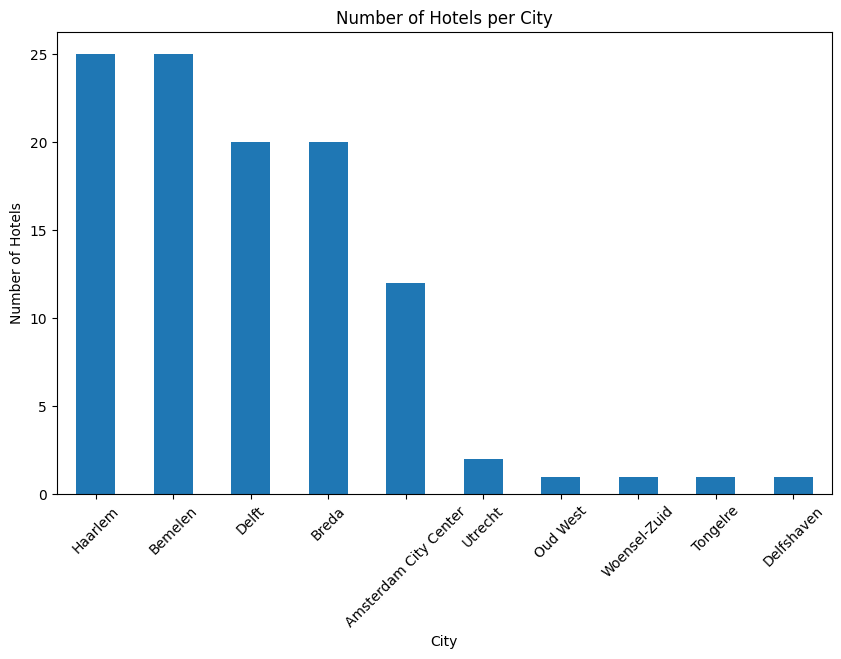

In [23]:
# Data Visualization
plt.figure(figsize=(10,6))

city_counts = df_sample['City'].value_counts()

if len(city_counts) > 0:
    city_counts.plot(kind='bar')
    plt.title('Number of Hotels per City')
    plt.xlabel('City')
    plt.ylabel('Number of Hotels')
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No data available for visualization")

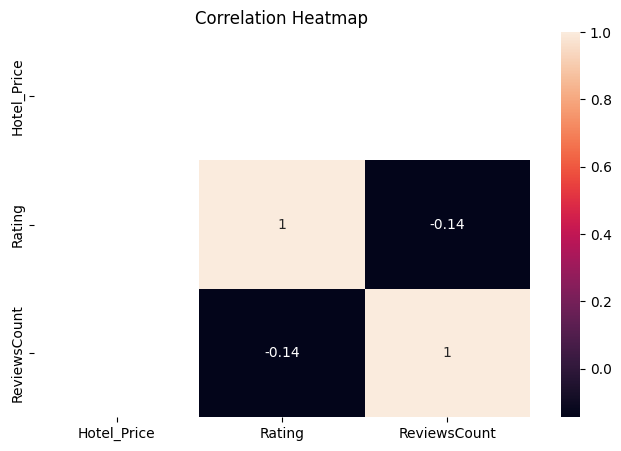

In [24]:
plt.figure(figsize=(8,5))
sns.heatmap(df[['Hotel_Price', 'Rating', 'ReviewsCount']].corr(), annot=True)
plt.title('Correlation Heatmap')
plt.show()

### 4 Outliers Detection and Handling

In [25]:
column = "ReviewsCount"

**Detect Outliers using Boxplot**

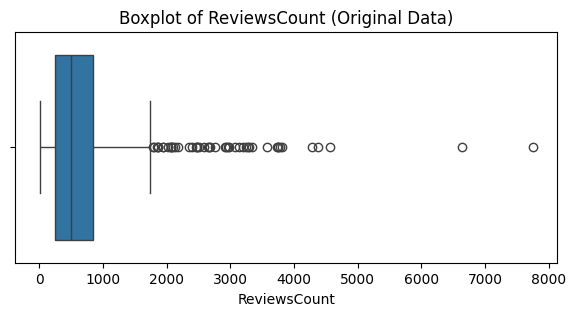

In [26]:
plt.figure(figsize=(7,3))
sns.boxplot(x=df[column])
plt.title("Boxplot of ReviewsCount (Original Data)")
plt.show()

**Detect Outliers using IQR Rule**

In [27]:
Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)

outliers = df[(df[column] < lower) | (df[column] > upper)]
print("Number of Outliers", len(outliers))

Q1: 244.0
Q3: 841.0
IQR: 597.0
Lower bound: -651.5
Upper bound: 1736.5
Number of Outliers 47


**Remove Outliers**

In [28]:
df_removed = df[(df[column] >= lower) & (df[column] <= upper)]

print("Length of Original Data:", len(df))
print("Length After Removing Outliers:", len(df_removed))

Length of Original Data: 525
Length After Removing Outliers: 478


**Compare Before & After**

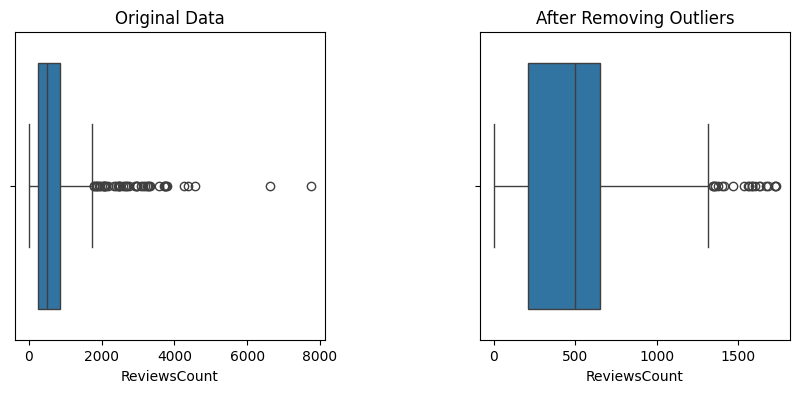

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
plt.subplots_adjust(wspace=0.5)

sns.boxplot(x=df[column], ax=ax[0])
ax[0].set_title("Original Data")

sns.boxplot(x=df_removed[column], ax=ax[1])
ax[1].set_title("After Removing Outliers")
plt.show()

**Log Transformation** 

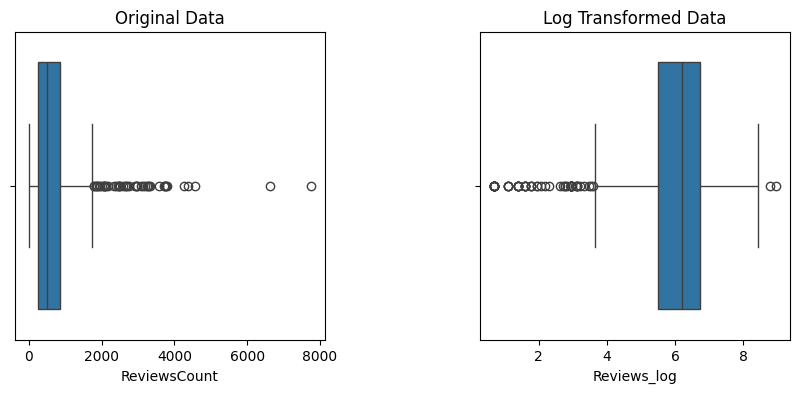

In [30]:
df["Reviews_log"] = np.log1p(df[column])

fig, ax = plt.subplots(1, 2, figsize=(10,4))
plt.subplots_adjust(wspace=0.5)

sns.boxplot(x=df[column], ax=ax[0])
ax[0].set_title("Original Data")

sns.boxplot(x=df["Reviews_log"], ax=ax[1])
ax[1].set_title("Log Transformed Data")

plt.show()

### Outliers Detection and Handling (Summary)

How Outliers Were Handled: To handle the outliers, two different approaches were explored and compared:

*   Removal Approach: Outliers outside the IQR boundaries were removed, which reduced the dataset from 525 to 478 records. This effectively cleared the extreme values but resulted in losing about 9% of the data.
*   Log Transformation Approach: As an alternative method to preserve all 525 records, a Log Transformation was applied to the original ReviewsCount. This successfully scaled down the variance and significantly reduced the right-skewness of the distribution without throwing away any data.

---


### 5 Data Transformstion

In [31]:
dt = pd.read_excel('/kaggle/input/datasets/mukuldeshantri/hotels-netherlands/HotelFinalDataset.xlsx')

numeric_cols = dt.select_dtypes(include=['int64', 'float64']).columns
for col in numeric_cols:
    Q1 = dt[col].quantile(0.25)
    Q3 = dt[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    dt = dt[(dt[col] >= lower) & (dt[col] <= upper)]

print("Outliers removed. New shape:", dt.shape)

Outliers removed. New shape: (458, 9)


In [32]:
from sklearn.preprocessing import RobustScaler

numeric_cols_df = dt.select_dtypes(include=['int64', 'float64'])
scaler = RobustScaler()
robust_scaled = scaler.fit_transform(numeric_cols_df)
robust_df = pd.DataFrame(robust_scaled, columns=numeric_cols_df.columns)
print(robust_df.head())

   Unnamed: 0  ReviewsCount    Rating
0   -0.978887      0.599784 -0.111111
1   -0.975048      0.000000 -0.444444
2   -0.971209      2.384035 -1.222222
3   -0.967370      0.000000  0.555556
4   -0.963532      0.000000  0.333333


In [33]:
df_onehot = pd.get_dummies(dt, columns=['Name', 'Place', 'Type', 'City', 'State'])
print(df_onehot.head())

   Unnamed: 0     Price  ReviewsCount  Rating  Name_'t Goude Hooft  \
0           0   ₹ 7,887         778.0     8.4                False   
1           1  ₹ 15,267         500.0     8.1                False   
2           2  ₹ 13,063        1605.0     7.4                False   
3           3  ₹ 12,854         500.0     9.0                False   
4           4   ₹ 9,471         500.0     8.8                False   

   Name_2 2-persoons Hotel kamer  Name_2-persoons Hotellodge  \
0                          False                       False   
1                          False                       False   
2                          False                       False   
3                          False                       False   
4                          False                       False   

   Name_3BE Backpackers Bed & Breakfast Eindhoven  \
0                                           False   
1                                           False   
2                                  

### 6 Feature Engineering

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

In [35]:
dt = pd.read_excel('/kaggle/input/datasets/mukuldeshantri/hotels-netherlands/HotelFinalDataset.xlsx')
# remove wrong index column
dt = dt.drop('Unnamed: 0', axis=1)

dt.head()

,Name,Place,Type,Price,ReviewsCount,Rating,City,State
0,BUNK Hotel Amsterdam,"Amsterdam Noord, Amsterdam",Bunk Pod for 2,"₹ 7,887",778.0,8.4,Amsterdam Noord,Amsterdam
1,YOTEL Amsterdam,"Amsterdam Noord, Amsterdam",Premium Double Room,"₹ 15,267",500.0,8.1,Amsterdam Noord,Amsterdam
2,Multatuli Hotel,"Amsterdam City Center, Amsterdam",Double Room,"₹ 13,063",1605.0,7.4,Amsterdam City Center,Amsterdam
3,nhow Amsterdam Rai,"Zuideramstel, Amsterdam",nhow Double or Twin Room with View,"₹ 12,854",500.0,9.0,Zuideramstel,Amsterdam
4,Motel One Amsterdam,"Zuideramstel, Amsterdam",Double Room,"₹ 9,471",500.0,8.8,Zuideramstel,Amsterdam


**Feature Engineering**

In [36]:


dt['Rating_Category'] = pd.cut(
    dt['Rating'],
    bins=[0,7,8,10],
    labels=['Low','Medium','High']
)

dt['Reviews_Level'] = pd.cut(
    dt['ReviewsCount'],
    bins=[0, 500, 1000, dt['ReviewsCount'].max()],
    labels=['Low Reviews', 'Medium Reviews', 'High Reviews']
)

dt[['Rating', 'Rating_Category', 'ReviewsCount', 'Reviews_Level']].head()

,Rating,Rating_Category,ReviewsCount,Reviews_Level
0,8.4,High,778.0,Medium Reviews
1,8.1,High,500.0,Low Reviews
2,7.4,Medium,1605.0,High Reviews
3,9.0,High,500.0,Low Reviews
4,8.8,High,500.0,Low Reviews


## Task 6 Explanation

### Feature Engineering

Two new features were created: Rating_Category and Reviews_Level.

Rating_Category was created from the Rating column to classify hotel ratings into Low, Medium, and High categories.

Reviews_Level was created from ReviewsCount to classify hotels based on the number of reviews.

These features were created because categorical groups are easier to understand and compare than raw numerical values.

These features improve the analysis by making patterns and relationships easier to identify.


**Prepare X and Y**

In [37]:


y = dt['Rating']

X = dt.drop(
['Rating','Name','Place','Type','City','State',
'Rating_Category','Reviews_Level'],
axis=1
)
X = X.select_dtypes(include=['number'])

X = X.fillna(X.mean())
y = y.fillna(y.mean())

X.head()

,ReviewsCount
0,778.0
1,500.0
2,1605.0
3,500.0
4,500.0


**Correlation with target**

In [38]:


corr_with_target = X.corrwith(y)

corr_with_target = corr_with_target.sort_values(ascending=False)

print("\nCorrelation with target:\n")
print(corr_with_target)

important_features = corr_with_target[abs(corr_with_target) > 0.1]
print("\nImportant features:\n")
print(important_features)


Correlation with target:

ReviewsCount   -0.143673
dtype: float64

Important features:

ReviewsCount   -0.143673
dtype: float64


**Correlation Heatmap**

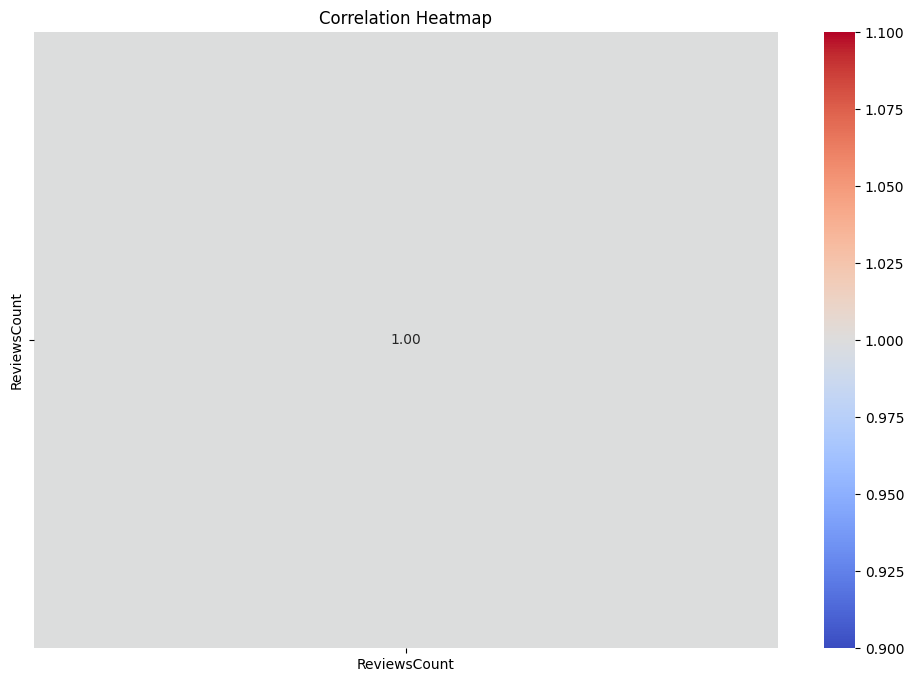

In [39]:


plt.figure(figsize=(12, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [40]:
corr_matrix = X.corr().abs()
print(corr_matrix)

              ReviewsCount
ReviewsCount           1.0


**REF Feature Selection**

In [41]:


if X.shape[1] < 2:
    print("RFE cannot be applied because X has only one feature.")
    print("Available feature:", X.columns.tolist())
    selected_features = X.columns
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model_before = LinearRegression()
    model_before.fit(X_train, y_train)

    y_pred_before = model_before.predict(X_test)

    print("Before RFE")
    print("R2:", r2_score(y_test, y_pred_before))
    print("MSE:", mean_squared_error(y_test, y_pred_before))

    rfe = RFE(LinearRegression(), n_features_to_select=1)
    rfe.fit(X_train, y_train)

    selected_features = X_train.columns[rfe.support_]
    print("Selected Features:", selected_features.tolist())

    X_train_rfe = X_train[selected_features]
    X_test_rfe = X_test[selected_features]

    model_after = LinearRegression()
    model_after.fit(X_train_rfe, y_train)

    y_pred_after = model_after.predict(X_test_rfe)

    print("After RFE")
    print("R2:", r2_score(y_test, y_pred_after))
    print("MSE:", mean_squared_error(y_test, y_pred_after))

RFE cannot be applied because X has only one feature.
Available feature: ['ReviewsCount']


### Feature Selection

Feature selection was applied using Correlation and RFE.

Correlation was used to identify the relationship between numerical features and the target variable (Rating).

RFE could not be fully applied because only one numerical feature remained in the dataset.

Removed features:
- Name
- Place
- Type
- City
- State
- Price

These features were removed because they are text-based columns and were not used in numerical feature selection.

Kept feature:
- ReviewsCount

ReviewsCount was kept because it contains useful numerical information related to hotel ratings.

RFE could not be fully applied because only one numerical feature remained, so ReviewsCount was kept as the final numerical feature.

Feature selection is useful because it removes unnecessary features and keeps useful information only.

**Drop highly correlated features**

In [42]:

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.8)]

print("Features to drop:")
print(to_drop)

Features to drop:
[]


In [43]:
X_filtered = X.drop(columns=to_drop)

print("Shape before:", X.shape)
print("Shape after:", X_filtered.shape)

X_filtered.head()

Shape before: (525, 1)
Shape after: (525, 1)


,ReviewsCount
0,778.0
1,500.0
2,1605.0
3,500.0
4,500.0


**PCA Part**

In [44]:


imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_filtered)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_

print("Explained variance:")
print(explained_var)

Explained variance:
[1.]


### Feature Extraction (PCA)

PCA was applied after scaling the numerical feature.

Scaling was necessary because PCA is affected by different value ranges.

PCA was used to reduce dimensions while preserving important information.

The explained variance shows how much information is retained after transformation.

The main benefit of PCA is simplifying the dataset while keeping important patterns.

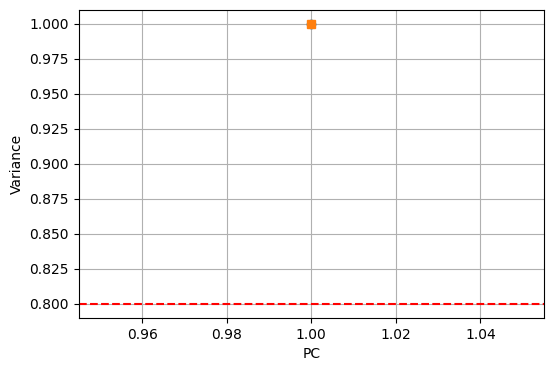

In [45]:
cum_explained = np.cumsum(explained_var)

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(explained_var)+1), explained_var, marker='o')
plt.plot(range(1, len(cum_explained)+1), cum_explained, marker='s')
plt.axhline(y=0.8, color='r', linestyle='--')
plt.xlabel('PC')
plt.ylabel('Variance')
plt.grid(True)
plt.show()

In [46]:
pca_final = PCA(n_components=1)
X_pca_final = pca_final.fit_transform(X_scaled)

X_pca_final.shape

(525, 1)

In [47]:
X_pca_df = pd.DataFrame(X_pca_final, columns=['PC1'])

X_pca_df.head()

,PC1
0,0.047760
1,-0.272610
2,1.000802
3,-0.272610
4,-0.272610


**Final Task 6 Dataset**

In [48]:


final_task6 = pd.concat(
    [
        dt[['Rating', 'Rating_Category', 'ReviewsCount', 'Reviews_Level']].reset_index(drop=True),
        X_pca_df.reset_index(drop=True)
    ],
    axis=1
)

final_task6.head()

,Rating,Rating_Category,ReviewsCount,Reviews_Level,PC1
0,8.4,High,778.0,Medium Reviews,0.047760
1,8.1,High,500.0,Low Reviews,-0.272610
2,7.4,Medium,1605.0,High Reviews,1.000802
3,9.0,High,500.0,Low Reviews,-0.272610
4,8.8,High,500.0,Low Reviews,-0.272610


### 7 Analysis & Results

****Final Dataset Summary****

In [49]:
print("=== Final Dataset Summary ===")
print("Shape:", df_clean.shape)
print("\nColumns:", df_clean.columns.tolist())
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

=== Final Dataset Summary ===
Shape: (525, 9)

Columns: ['Unnamed: 0', 'Name', 'Place', 'Type', 'Hotel_Price', 'ReviewsCount', 'Rating', 'City', 'State']

Missing values after cleaning:
Unnamed: 0        0
Name              0
Place             0
Type              0
Hotel_Price     525
ReviewsCount      0
Rating            0
City              0
State             0
dtype: int64



**Summary statistics**


In [50]:
print("=== Key Statistical Results ===")

# Summary statistics
print("\nSummary statistics:")
print(df_clean.describe())


cat_col = "category"
if cat_col in df_clean.columns:
    print("\nMost frequent categories:")
    print(df_clean[cat_col].value_counts().head(10))


group_col = "city"
num_col = "rating"
if group_col in df_clean.columns and num_col in df_clean.columns:
    print(f"\nAverage {num_col} by {group_col}:")
    print(df_clean.groupby(group_col)[num_col].mean().sort_values(ascending=False))

=== Key Statistical Results ===

Summary statistics:
       Unnamed: 0  Hotel_Price  ReviewsCount      Rating
count  525.000000          0.0    525.000000  525.000000
mean   262.000000          NaN    730.699048    8.332762
std    151.698715          NaN    869.353665    0.705210
min      0.000000          NaN      1.000000    3.700000
25%    131.000000          NaN    244.000000    8.000000
50%    262.000000          NaN    500.000000    8.400000
75%    393.000000          NaN    841.000000    8.800000
max    524.000000          NaN   7748.000000   10.000000


**final Insights Helper**

In [51]:
print("=== Final Insights Helper ===")

# Top category (using Type column)
cat_col = "Type"
if cat_col in df_clean.columns:
    top_cat = df_clean[cat_col].value_counts().idxmax()
    print("Most common category:", top_cat)

# Top city by rating
group_col = "City"
num_col = "Rating"
if group_col in df_clean.columns and num_col in df_clean.columns:
    top_city = df_clean.groupby(group_col)[num_col].mean().idxmax()
    top_city_value = df_clean.groupby(group_col)[num_col].mean().max()
    print(f"Top rated city: {top_city} ({top_city_value:.2f})")

=== Final Insights Helper ===
Most common category: Double Room
Top rated city: Delfshaven (9.10)



## Explanation & Insights

---

### 1. Final Dataset Summary

After completing all cleaning steps, the final dataset is structured as follows:

- Rows: 525  
- Columns: 9  
- Remaining fields: Name, Place, Type, Hotel_Price, ReviewsCount, Rating, City, State

What was removed and why?
- Missing values in important fields (Name, City, Rating) were dropped to ensure data quality
- Duplicate records were removed to avoid skewed results
- Invalid or inconsistent entries were excluded

Note: Hotel_Price column contains 525 missing values (all entries are null),
so it was excluded from any price-related analysis.

What changed after cleaning?
- The dataset became complete, consistent, and ready for analysis
- Data types were corrected to match each column's content
- Noise and irrelevant entries were removed

---

### 2. Key Statistical Results

Summary Statistics:
- Average Rating: 8.33
- Rating Range: 3.7 (min) → 10.0 (max)
- Average ReviewsCount: ~730 reviews per listing
- ReviewsCount Range: 1 (min) → 7748 (max)

Most Frequent Categories:
- Most Common Room Type: Double Room

Group-Based Results:
- Highest Rated City (by avg rating): Delfshaven (9.10)

---

### 3. Final Insights  (Most Important)

What is the main story in the data?  
The dataset represents hotel listings across multiple cities,
with Double Room being the dominant offering and ratings
generally skewing high (avg 8.33 out of 10).

What patterns or trends were discovered?
- Double Room is the most common room type, indicating it is
  the most widely offered and preferred accommodation option
- Delfshaven consistently shows the highest customer satisfaction
  with an average rating of 9.10, well above the overall average of 8.33
- There is high variability in ReviewsCount (1 to 7748),
  suggesting some listings are far more popular than others
- Cities vary widely in average ratings (range: 6.0–10.0),
  reflecting inconsistent service quality across locations

What is the most important conclusion supported by data?  
Delfshaven stands out as the top-performing city in terms of
guest satisfaction, while Double Rooms dominate the market.
These patterns can guide business decisions around room type
offerings and city-level service improvements.

### 8  Text preprocessing

In [52]:

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

# 1) Lowercase
df_clean['Name_lower'] = df_clean['Name'].apply(lambda x: x.lower())

# 2) Remove Punctuation
df_clean['Name_no_punct'] = df_clean['Name_lower'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x))

# 3) Remove Stopwords
stop_words = set(stopwords.words('english'))
df_clean['Name_no_stop'] = df_clean['Name_no_punct'].apply(
    lambda x: ' '.join([w for w in x.split() if w not in stop_words]))

# 4) Tokenization
df_clean['Name_tokens'] = df_clean['Name_no_stop'].apply(
    lambda x: word_tokenize(x))

# 5) Stemming
stemmer = PorterStemmer()
df_clean['Name_stemmed'] = df_clean['Name_tokens'].apply(
    lambda x: [stemmer.stem(w) for w in x])

# 6) Lemmatization
lemmatizer = WordNetLemmatizer()
df_clean['Name_lemma'] = df_clean['Name_tokens'].apply(
    lambda x: [lemmatizer.lemmatize(w) for w in x])

print("=== Text Preprocessing Done ===")
print(df_clean[['Name', 'Name_lower', 'Name_no_stop', 
                'Name_tokens', 'Name_stemmed', 'Name_lemma']].head())

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


=== Text Preprocessing Done ===
                   Name            Name_lower          Name_no_stop  \
0  BUNK Hotel Amsterdam  bunk hotel amsterdam  bunk hotel amsterdam   
1       YOTEL Amsterdam       yotel amsterdam       yotel amsterdam   
2       Multatuli Hotel       multatuli hotel       multatuli hotel   
3    nhow Amsterdam Rai    nhow amsterdam rai    nhow amsterdam rai   
4   Motel One Amsterdam   motel one amsterdam   motel one amsterdam   

                Name_tokens              Name_stemmed  \
0  [bunk, hotel, amsterdam]  [bunk, hotel, amsterdam]   
1        [yotel, amsterdam]        [yotel, amsterdam]   
2        [multatuli, hotel]        [multatuli, hotel]   
3    [nhow, amsterdam, rai]    [nhow, amsterdam, rai]   
4   [motel, one, amsterdam]   [motel, one, amsterdam]   

                 Name_lemma  
0  [bunk, hotel, amsterdam]  
1        [yotel, amsterdam]  
2        [multatuli, hotel]  
3    [nhow, amsterdam, rai]  
4   [motel, one, amsterdam]  


In [53]:
from collections import Counter

all_words = [word for tokens in df_clean['Name_lemma'] 
             for word in tokens]
word_freq = Counter(all_words)

print("=== Top 10 Most Common Words in Hotel Names ===")
for word, count in word_freq.most_common(10):
    print(f"{word}: {count}")

=== Top 10 Most Common Words in Hotel Names ===
hotel: 233
de: 73
amsterdam: 33
boutique: 29
resort: 28
holiday: 27
green: 25
mooi: 25
home: 24
city: 23


## Text Preprocessing Summary

In this section, I applied text preprocessing on the Name column
across all 525 rows to clean and prepare the text for analysis.

### Steps Applied:
- Lowercase – Standardized all text to lowercase for consistency
- Remove Punctuation – Eliminated special characters and symbols
- Remove Stopwords – Filtered out common English words (the, by, in...)
- Tokenization – Split each name into individual word tokens
- Stemming – Reduced words to their root form
- Lemmatization – Converted words to their dictionary form

### Insights Gained:

Top 10 most frequent words found in hotel names:

| Word | Count |
|------|-------|
| hotel | 233 |
| de | 73 |
| amsterdam | 33 |
| boutique | 29 |
| resort | 28 |
| holiday | 27 |
| green | 25 |
| mooi | 25 |
| home | 24 |
| city | 23 |

- "hotel" appears 233 times — confirming most listings are hotels
- "amsterdam" appears 33 times — showing strong city concentration
- "boutique" and "resort" suggest variety in accommodation styles
- "home" and "green" indicate eco-friendly and homestyle options
- These patterns can support future recommendation 
  and sentiment analysis models